# 03 · Fig. 1: the two annual lows and PV capacity

**Purpose.** Draw Fig. 1 and show the numbers behind it.

**Paper section served.** I Introduction.

**Inputs**

- `data/interim/network_30min.parquet` from notebook 01.
- `data/interim/pv_annual.parquet` from notebook 02.

**Paper artifacts**

- `results/figures/fig1.png` (600 dpi) and `fig1.pdf`: Fig. 1, the annual overnight low and daytime low over PV capacity.
- `results/tables/fig1_data.csv`: the values plotted.

**Supporting checks.** None. The annual maximum and energy by year are in `results/checks/check_annual_summary.csv` (notebook 01).

**Main process**

1. Set up.
2. Each year's two lows and PV capacity.
3. Draw and save Fig. 1.
4. Result.

An earlier version of this figure, with maximum demand and annual energy, is in `exploration/01_conference/A2_superseded_figures.ipynb`.

## 1. Set up

`set_style` applies the shared figure style: one IEEE column wide, 8 pt serif text, no title inside the figure.

In [1]:
import pandas as pd

from pynmdf import plots, targets
from pynmdf.config import load_config

cfg = load_config()
interim, figures, tables = (cfg["dirs"][key] for key in ("interim", "figures", "tables"))
plots.set_style()

pd.set_option("display.width", 220, "display.float_format", "{:,.1f}".format)
total = pd.read_parquet(interim / "network_30min.parquet")["total_mw"]
capacity = pd.read_parquet(interim / "pv_annual.parquet")["kwp"]

## 2. Each year's two lows and PV capacity

The year's minimum is split in two: the **overnight low** is the lowest valid half hour between 00:00 and 06:00, and the **daytime low** the lowest between 09:00 and 17:00. The year's minimum is the lower of the two. PV capacity is the published network total at 30 June of each year, in MW.

In [2]:
annual = targets.annual_window_lows(total, cfg["targets"]["troughs"]).assign(
    pv_mw=capacity / 1000
)
annual.to_csv(tables / "fig1_data.csv")
annual.T

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
overnight_low_mw,"1,368.1","1,432.6","1,474.3","1,495.1","1,473.0","1,429.5","1,387.6","1,428.3","1,393.2","1,419.6","1,434.9"
daytime_low_mw,"1,832.6","1,891.4","1,888.2","1,901.7","1,759.2","1,671.0","1,357.4","1,457.9","1,080.0","1,019.2",880.1
pv_mw,230.0,287.1,345.8,448.7,619.9,780.2,"1,050.4","1,291.3","1,562.6","1,881.7","2,083.7"


## 3. Fig. 1

Two panels share the year axis. The top panel draws the overnight low and the daytime low as lines, on an axis zoomed to their range. The bottom panel draws PV capacity as bars from zero. Two panels are used in place of two y-axes on one panel, so each quantity is read against its own scale.

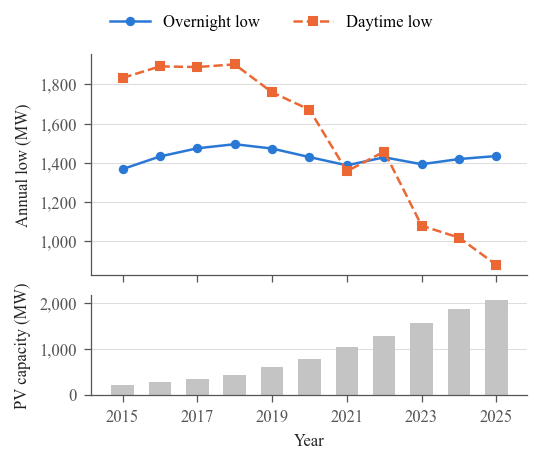

In [3]:
figure = plots.annual_lows_and_pv(annual)
plots.save_figure(figure, figures, "fig1")

## 4. Result

Each series in its first and last year, and the years in which the daytime low sits below the overnight low.

In [4]:
ends = annual.loc[[annual.index[0], annual.index[-1]]].T
ends["change_pct"] = 100 * (ends.iloc[:, 1] / ends.iloc[:, 0] - 1)

daytime_lower = annual.index[annual["daytime_low_mw"] < annual["overnight_low_mw"]]
print("Years in which the daytime low is below the overnight low:", daytime_lower.tolist())
ends

Years in which the daytime low is below the overnight low: [2021, 2023, 2024, 2025]


year,2015,2025,change_pct
overnight_low_mw,"1,368.1","1,434.9",4.9
daytime_low_mw,"1,832.6",880.1,-52.0
pv_mw,230.0,"2,083.7",806.0
